# 01 · Auditoría y preparación para imputación

**IPre Pedro Saa · 9 de noviembre de 2026**

Este notebook revisa las fuentes, distingue los metabolitos disponibles de los
candidatos a imputación y prepara Ishii (A) e Ishii + MMC2 (B). No entrena
imputadores ni completa huecos. Las decisiones de disponibilidad son preliminares:
la confiabilidad se evaluará después, con cinco bloques externos y tres internos.

Ejecutar de principio a fin desde la raíz del proyecto. Solo necesita pandas,
NumPy, matplotlib, openpyxl, pypdf e IPython. Los resultados se escriben en
`auditoria/`; al repetirlo se reemplazan esas mismas salidas.

**Fuentes y diagnóstico.** El punto de partida de esta auditoría fue
`IPre_Ampliado.zip` (22 de octubre), posterior a la refactorización de siete
metabolitos. Se conservan sus libros originales, la base auditada y la conversión
nominal de Gerosa. Se reemplaza la selección fija de diez variables por una
auditoría completa y una selección explícita. Los resultados de imputación
anteriores no se incluyen en esta entrega ni validan el panel nuevo.

## 1. Cargar y reconocer las fuentes

Los cuatro Excel son las fuentes tabulares. La SQLite auditada es una **capa
procesada**, útil por sus coordenadas de origen; verificamos sus concentraciones
contra los Excel antes de usarla. MMC4 aporta un modelo y nombres de metabolitos,
no concentraciones. Los PDF contienen los métodos. No se usan matrices imputadas.

In [16]:
from pathlib import Path
import hashlib
import json
import sqlite3
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import openpyxl
import pandas as pd
from IPython.display import display
from pypdf import PdfReader

RAIZ = Path.cwd()
assert (RAIZ / 'sources/ishii.xlsx').exists(), 'Abrir desde la raíz del proyecto'
FUENTES = RAIZ / 'sources'
SALIDA = RAIZ / 'auditoria'
SALIDA.mkdir(exist_ok=True)
(SALIDA / 'figuras').mkdir(exist_ok=True)

archivos = [
    'ishii.xlsx', 'mmc2.xlsx', 'mmc3.xlsx', 'mmc4.xlsx',
    'Ishii_methods.pdf', 'Gerosa_methods.pdf', 'ecoli_auditada_v3.db',
]
huellas = {}
for nombre in archivos:
    archivo = FUENTES / nombre
    assert archivo.is_file(), f'Falta la fuente {nombre}'
    huellas[nombre] = hashlib.sha256(archivo.read_bytes()).hexdigest()

libros = {}
for estudio, nombre in [('ISHII2007', 'ishii'), ('MMC2', 'mmc2'),
                        ('MMC3', 'mmc3'), ('MMC4', 'mmc4')]:
    libros[estudio] = openpyxl.load_workbook(
        FUENTES / f'{nombre}.xlsx', data_only=True
    )

with sqlite3.connect((FUENTES / 'ecoli_auditada_v3.db').as_uri() + '?mode=ro',
                     uri=True) as conexion:
    assert conexion.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
    mediciones = pd.read_sql_query(
        "SELECT * FROM audit_measurements_readable WHERE entity_type='metabolite'",
        conexion,
    )
    analitos = pd.read_sql_query(
        "SELECT * FROM audit_analytes WHERE entity_type='metabolite'", conexion
    )
    muestras_s2 = pd.read_sql_query('SELECT * FROM ishii_samples', conexion)
    columnas_ishii = pd.read_sql_query(
        'SELECT * FROM ishii_metabolite_source_columns', conexion
    )
    condiciones = pd.read_sql_query('SELECT * FROM conditions', conexion)

modelo = pd.read_excel(FUENTES / 'mmc4.xlsx', sheet_name='metabolites')
modelo = modelo.rename(columns={modelo.columns[0]: 'id_modelo',
                                modelo.columns[1]: 'descripcion'})
assert len(modelo) == 80
assert mediciones.measurement_uid.is_unique
assert not mediciones.duplicated(['analyte_id', 'sample_key']).any()
assert mediciones.is_imputed.eq(0).all()
# Comprobar también etiquetas y protocolos, no solo números.
leyenda = {}
for fila in libros['ISHII2007']['generals']:
    if fila[2].value and 'Method' in str(fila[2].value):
        leyenda[fila[1].fill.fgColor.rgb] = str(fila[2].value).split(':')[-1].strip()
for fila in analitos.itertuples():
    hoja = 'metabolites' if fila.dataset_id == 'ISHII2007' else 'Metabolite concentrations'
    if fila.compartment == 'extracellular':
        hoja = 'extracellular'
    columna = 2 if fila.dataset_id == 'MMC2' else 1
    celda = libros[fila.dataset_id][hoja].cell(fila.source_row, columna)
    assert str(celda.value).strip() == fila.original_label.strip()
    if fila.dataset_id == 'ISHII2007' and fila.compartment == 'intracellular':
        assert leyenda.get(celda.fill.fgColor.rgb) == fila.protocol
display(mediciones.groupby(['dataset_id', 'compartment']).agg(
    posiciones=('value_original', 'size'),
    medidas=('value_original', 'count'),
    analitos=('analyte_id', 'nunique'),
    muestras=('sample_key', 'nunique'),
))

posiciones  medidas  analitos  muestras
dataset_id compartment                                           
ISHII2007  extracellular         264      264         8        33
           intracellular       19686     4813       579        34
MMC2       intracellular         344      342        43         8
MMC3       intracellular         189      189        21         9

## 2. Verificar concentraciones, ausencias y muestras

Se comprueba cada celda y cada SD disponible. Los ceros se conservan como
mediciones; los blancos Ishii se etiquetan como no detectados, sin distinguir
cuánto está bajo el límite de detección. Los dos `NaN` textuales de MMC2 son
cuantificaciones no fiables según la nota B47. No suponemos faltantes aleatorios.

Para Ishii mantenemos 30 muestras. **Corrección documental:** KO05x carece de fila
inequívoca en S2, pero `generals!B20:C20` incluye la columna F entre los knockouts
cultivados a D = 0,2 h⁻¹. Se registra esa evidencia; no se inventan fecha ni
biomasa. KO05x y KO05 siguen siendo cultivos distintos y pertenecen al mismo
grupo de perturbación para excluirlos conjuntamente en validación.

In [17]:
valores_excel = []
for fila in mediciones.itertuples():
    hoja = libros[fila.dataset_id][fila.source_sheet]
    bruto = hoja[fila.source_cell].value
    valores_excel.append(bruto)
    if isinstance(bruto, (int, float)):
        assert np.isfinite(bruto)
        assert pd.notna(fila.value_original)
        assert np.isclose(bruto, fila.value_original, rtol=1e-12, atol=1e-14)
    else:
        assert bruto is None or bruto == 'NaN', (fila.measurement_uid, bruto)
        assert pd.isna(fila.value_original)
    if pd.notna(fila.source_uncertainty_cell):
        sd = hoja[fila.source_uncertainty_cell].value
        if isinstance(sd, (int, float)):
            assert np.isclose(sd, fila.uncertainty_original, rtol=1e-12)
        else:
            assert sd is None or sd == 'NaN'
            assert pd.isna(fila.uncertainty_original)

mediciones['valor_original_excel'] = valores_excel
mediciones['es_cero_reportado'] = mediciones.value_original.eq(0)
assert len(mediciones) == 20483
assert (mediciones.value_original.dropna() >= 0).all()
assert 'not detected' in libros['ISHII2007']['generals']['A49'].value
assert 'NaN' in libros['MMC2']['Metabolite concentrations']['B47'].value

ids_originales = mediciones.query(
    "dataset_id == 'ISHII2007' and compartment == 'intracellular'"
).sample_key.unique()
columnas = columnas_ishii.query("source_sheet == 'metabolites'").copy()
columnas = columnas[columnas.sample_id_original.isin(ids_originales)]
for fila in columnas.itertuples():
    hoja = libros['ISHII2007']['metabolites']
    assert hoja[f'{fila.source_column}2'].value == fila.sample_id_original
    assert str(hoja[f'{fila.source_column}3'].value) == fila.source_series_id
meta_ishii = columnas[['sample_id_original', 'source_column',
                       'source_series_id', 'source_sample_label']].rename(
    columns={'sample_id_original': 'sample_id',
             'source_series_id': 'serie_analitica'}
)
meta_ishii = meta_ishii.merge(
    muestras_s2[['sample_id', 'dilution_rate_h_inv', 'knockout_gene',
                 'culture_date', 'strain_background']],
    on='sample_id', how='left', validate='one_to_one',
)
meta_ishii['evidencia_dilucion'] = 'Ishii_methods.pdf, Tabla S2, p.47'
ko05x = meta_ishii.sample_id.eq('KO05x')
assert meta_ishii.loc[ko05x, 'source_column'].item() == 'F'
assert '0.2 h-1' in libros['ISHII2007']['generals']['C20'].value
meta_ishii.loc[ko05x, 'dilution_rate_h_inv'] = 0.2
meta_ishii.loc[ko05x, 'knockout_gene'] = 'pfkA'
meta_ishii.loc[ko05x, 'strain_background'] = 'E. coli K-12 BW25113'
meta_ishii.loc[ko05x, 'evidencia_dilucion'] = 'ishii.xlsx, generals!B20:C20'
meta_ishii['incluida'] = meta_ishii.dilution_rate_h_inv.eq(0.2)
meta_ishii['grupo'] = meta_ishii.knockout_gene.fillna('WT')
meta_ishii['serie_familia'] = meta_ishii.serie_analitica.astype(str).str.replace(
    '*', '', regex=False
)
meta_ishii['dataset_id'] = 'ISHII2007'
meta_ishii['carbono'] = 'glucosa'
meta_ishii['cultivo'] = 'quimiostato limitado por glucosa'
meta_ishii['rol'] = np.where(meta_ishii.incluida, 'entrenamiento_y_evaluacion',
                           'excluida_otra_dilucion')
meta_ishii['pendiente'] = np.where(ko05x, 'Fecha y correspondencia exacta con S2', '')
cohorte = sorted(meta_ishii.loc[meta_ishii.incluida, 'sample_id'])
assert len(cohorte) == 30
assert len(ids_originales) == 34

# La hoja de muestreo muestra t ~ 5,9 h y OD ~ 1 para metabolómica de glucosa.
# Es una lectura gráfica aproximada; no se usa para ajustar concentraciones.
meta_mmc2 = condiciones.query("dataset_id == 'MMC2'").copy()
meta_mmc2 = meta_mmc2.rename(columns={'condition_id': 'sample_id',
                                     'carbon_source': 'carbono'})
meta_mmc2['grupo'] = meta_mmc2.sample_id
meta_mmc2['incluida'] = True
meta_mmc2['cultivo'] = 'lote, fase exponencial; 5 g/L de una fuente de carbono'
meta_mmc2['rol'] = 'solo_entrenamiento_B'
meta_mmc2['evidencia_condicion'] = 'Gerosa_methods.pdf p.7; MMC2 Physiology'
meta_mmc2['tiempo_muestreo_aprox_h'] = np.nan
meta_mmc2['OD600_muestreo_aprox'] = np.nan
meta_mmc2.loc[meta_mmc2.sample_id.eq('MMC2_GLUCOSE'),
              ['tiempo_muestreo_aprox_h', 'OD600_muestreo_aprox']] = [5.9, 1.0]
meta_mmc2['evidencia_muestreo'] = 'MMC2 Measurement Sampling, figura incrustada'
metadatos = pd.concat([meta_ishii, meta_mmc2], ignore_index=True)
metadatos = metadatos.set_index('sample_id').sort_index()
display(mediciones.groupby(['dataset_id', 'absence_code']).size().rename('n'))
print('Cohorte Ishii:', len(cohorte), '| MMC2:', len(meta_mmc2))

dataset_id  absence_code                          
ISHII2007   not_detected_unspecified                  14873
            reported                                   5077
MMC2        not_reported_unreliable_quantification        2
            reported                                    342
MMC3        reported                                    189
Name: n, dtype: int64

Cohorte Ishii: 30 | MMC2: 9


## 3. Homologar sin forzar equivalencias

El inventario conserva cada **fila analítica**, su protocolo y su compartimento;
no todas las filas representan moléculas diferentes. El diccionario siguiente
recoge equivalencias aceptadas por nombre completo y forma química. Para
nucleótidos se usan las abreviaturas bioquímicas convencionales, respaldadas por
los nombres completos de MMC2 y KEGG. Esto no verifica retrospectivamente la
pureza de cada estándar experimental.

Citrato mantiene la fila Nucleotide 523 del protocolo anterior. La fila Anion
133 se conserva, sin combinarla ni rellenar desde otra técnica. NADPH se toma
de su fila monovalente; la señal «Divalent ion from NADPH» no se suma ni se usa
como reemplazo. Isocitrato tiene dos filas sin mediciones; queda pendiente de
selección de protocolo y fuera de las matrices.

Se dejan pendientes las etiquetas que no resuelven estereoquímica (por ejemplo
Malate frente a L-Malate), mezclas y posiciones no especificadas. La señal
2pg+3pg de Gerosa nunca se equipara a 3pg de Ishii. Glucosa-1-fosfato no es
galactosa-1-fosfato. Un metabolito puede estar identificado aunque no exista en
el modelo MMC4: se conserva la clave de Gerosa sin inventar un nodo del modelo.

In [18]:
# Clave MMC2: (fila Ishii, etiqueta Ishii esperada).
equivalencias = {
    'pyr': (9, 'Pyruvate'),
    'fum': (29, 'Fumarate'),
    'succ': (33, 'Succinate'),
    'akg': (64, '2-Oxoglutarate'),
    'pep': (96, 'Phosphoenolpyruvate'),
    'dhap': (101, 'Dihydroxyacetone phosphate'),
    's7p': (179, 'Sedoheptulose-7-phosphate'),
    'ade': (324, 'Adenine'),
    'cit': (523, 'Citrate'),
    'cAMP': (535, 'cAMP'),
    'amp': (538, 'AMP'),
    'gmp': (540, 'GMP'),
    'adp': (554, 'ADP'),
    'gdp': (558, 'GDP'),
    'atp': (566, 'ATP'),
    'gtp': (568, 'GTP'),
    'nad': (576, 'NAD'),
    'nadh': (578, 'NADH'),
    'nadp': (579, 'NADP'),
    'nadph': (580, 'NADPH'),
}
# Correspondencias propuestas que requieren evidencia adicional.
pendientes = {
    52: ('asp', 'Aspartato sin estereoquímica; protocolo Anion alternativo'),
    53: ('mal-L', 'Ishii no especifica L frente a D'),
    66: ('glu', 'Ishii no especifica L; no usar la señal compuesta Glu+Albizziine'),
    102: ('glyc3p', 'Glycerophosphorate no fija posición ni estereoquímica'),
    124: ('2pg+3pg', 'Un componente no equivale a la medición conjunta'),
    131: ('cit', 'Mezcla Isocitrate + Citrate; no repartir'),
    132: ('icit', 'Dos protocolos sin valores; no seleccionar automáticamente'),
    133: ('cit', 'Protocolo Anion alternativo; se conserva la fila 523 fijada antes'),
    143: ('e4p', 'No se especifica D en la etiqueta Ishii'),
    164: ('ru5p-D', 'No se especifica D en la etiqueta Ishii'),
    165: ('r5p', 'Etiqueta Ishii sin estereoquímica; MMC2 especifica alpha-D'),
    172: ('', 'Glucosa-1-fosfato no tiene referencia MMC2; no usar gal1p'),
    173: ('f6p', 'No se especifica D en la etiqueta Ishii'),
    174: ('g6p', 'No se especifica D en la etiqueta Ishii'),
    176: ('13dpg', '2,3-difosfoglicerato no es 1,3-bisfosfoglicerato'),
    178: ('6pgc', 'No se especifica D en la etiqueta Ishii'),
    189: ('fdp', 'Posiciones 1,6 compatibles; estereoquímica no explícita'),
    314: ('asn', 'Asn/Asparagine: estándar y estereoquímica por confirmar'),
    320: ('asp', 'Asp/Aspartate: estándar y estereoquímica por confirmar'),
    342: ('gln', 'Gln frente a L-Glutamine: estereoquímica por confirmar'),
    348: ('glu', 'Señal Glu+Albizziine compuesta; no usar como glutamato'),
    387: ('phe', 'Phe y nombre MMC2 con errata; revisar estándar'),
    400: ('arg', 'Arg/Arginine: estándar y estereoquímica por confirmar'),
    418: ('tyr', 'Tyr/Tyrosine: estándar y estereoquímica por confirmar'),
    524: ('icit', 'Dos protocolos sin valores; no seleccionar automáticamente'),
    542: ('nadph', 'Señal divalente alternativa; no sumar a la fila 580'),
}

hoja_mmc2 = libros['MMC2']['Metabolite concentrations']
nombres_mmc2 = {hoja_mmc2.cell(i, 2).value: hoja_mmc2.cell(i, 3).value
                 for i in range(3, 46)}
filas_mmc2 = {hoja_mmc2.cell(i, 2).value: i for i in range(3, 46)}
maestra = analitos.rename(columns={'metabolite_id': 'id_modelo_previo'}).copy()
maestra['metabolito'] = ''
maestra['nombre_homologado'] = ''
maestra['estado_homologacion'] = 'pendiente_sin_equivalencia_revisada'
maestra['justificacion'] = 'Conservar etiqueta original; no usar automáticamente'
maestra['contraparte_propuesta'] = ''
maestra['fila_elegida_ishii'] = False

for metabolito, (numero, etiqueta) in equivalencias.items():
    aid = f'ISHII:metabolites:{numero}'
    seleccion = maestra.analyte_id.eq(aid)
    assert seleccion.sum() == 1
    assert maestra.loc[seleccion, 'original_label'].item() == etiqueta
    assert libros['ISHII2007']['metabolites'].cell(numero, 1).value == etiqueta
    maestra.loc[seleccion, 'metabolito'] = metabolito
    maestra.loc[seleccion, 'nombre_homologado'] = nombres_mmc2[metabolito]
    maestra.loc[seleccion, 'estado_homologacion'] = 'aceptada_nominal'
    maestra.loc[seleccion, 'fila_elegida_ishii'] = True
    maestra.loc[seleccion, 'justificacion'] = (
        f'Ishii metabolites!A{numero}; MMC2 B{filas_mmc2[metabolito]}:'
        f'C{filas_mmc2[metabolito]}; misma entidad nominal intracelular'
    )

for numero, (candidato, motivo) in pendientes.items():
    seleccion = maestra.analyte_id.eq(f'ISHII:metabolites:{numero}')
    maestra.loc[seleccion, 'contraparte_propuesta'] = candidato
    maestra.loc[seleccion, 'justificacion'] = motivo

for estudio in ['MMC2', 'MMC3']:
    for indice in maestra.index[maestra.dataset_id.eq(estudio)]:
        etiqueta = maestra.loc[indice, 'original_label']
        clave = '2pg+3pg' if etiqueta == '3pg+2pg' else etiqueta
        maestra.loc[indice, 'metabolito'] = clave
        maestra.loc[indice, 'nombre_homologado'] = nombres_mmc2.get(clave, etiqueta)
        maestra.loc[indice, 'estado_homologacion'] = 'identidad_fuente_Gerosa'
        maestra.loc[indice, 'justificacion'] = 'Nombre completo y etiqueta en la fuente'

maestra.loc[maestra.composite.eq(1), 'estado_homologacion'] = 'medicion_compuesta'
maestra.loc[maestra.compartment.eq('extracellular'),
            'estado_homologacion'] = 'fuera_alcance_extracelular'
maestra['nombre_repetido_en_base'] = maestra.duplicated(
    ['dataset_id', 'compartment', 'original_label'], keep=False
)
# Vinculación al modelo por la clave explícita, solo si ese nodo existe.
ids_modelo = set(modelo.id_modelo)
maestra['id_modelo'] = maestra.metabolito.map(
    lambda x: x + '[c]' if x + '[c]' in ids_modelo else ''
)
maestra['id_quimico_externo'] = ''
ids_kegg = {'dhap': 'C00111', 'amp': 'C00020', 'gmp': 'C00144',
            'gdp': 'C00035', 'gtp': 'C00044', 'cAMP': 'C00575'}
maestra['id_quimico_externo'] = maestra.metabolito.map(ids_kegg).fillna('')
maestra['evidencia_externa'] = maestra.id_quimico_externo.map(
    lambda x: 'https://www.kegg.jp/entry/' + x if x else ''
)
display(maestra.loc[maestra.fila_elegida_ishii,
                   ['original_label', 'metabolito', 'protocol', 'id_modelo']])

,original_label,metabolito,protocol,id_modelo
68,Pyruvate,pyr,Anion,pyr[c]
88,Fumarate,fum,Anion,fum[c]
92,Succinate,succ,Anion,succ[c]
123,2-Oxoglutarate,akg,Anion,akg[c]
155,Phosphoenolpyruvate,pep,Anion,pep[c]
160,Dihydroxyacetone phosphate,dhap,Anion,dhap[c]
238,Sedoheptulose-7-phosphate,s7p,Anion,s7p[c]
383,Adenine,ade,Cation,
582,Citrate,cit,Nucleotide,cit[c]
594,cAMP,cAMP,Nucleotide,


## 4. Verificar unidades y convertir a mM

Ishii ya declara mM (`generals!A10:B10`). Gerosa declara µmol/gCDW.
MMC2 `Conversion Factors!A5:B6` define **2,3 mL/gCDW** como volumen citosólico,
aplicable a todas las condiciones. El método de Gerosa (PDF p.9) respalda la
conversión para el estudio estacionario y la transición. **No hay respaldo para
usar 12,3 como este factor** en las fuentes revisadas.

Se divide concentración y SD de Gerosa por 2,3; µmol/mL equivale a mM. No se
reconvierte Ishii. La incertidumbre del volumen no está especificada, y las SD
convertidas quedan condicionadas al factor nominal. Las SD de referencia Ishii
no se asignan a cada muestra como si fueran su incertidumbre individual.

In [19]:
factor_hoja = libros['MMC2']['Conversion Factors']
volumen = float(factor_hoja['B6'].value)
assert volumen == 2.3
assert 'cytosolic volume' in factor_hoja['A5'].value
assert factor_hoja['B5'].value == 'All conditions'
assert 'ml/gCDW' in factor_hoja['A6'].value
assert libros['ISHII2007']['generals']['B10'].value == 'mM'
metodo_gerosa = PdfReader(FUENTES / 'Gerosa_methods.pdf').pages[8].extract_text()
assert 'intracellular cytosolic volume' in metodo_gerosa

mediciones['divisor_conversion'] = np.where(
    mediciones.dataset_id.eq('ISHII2007'), 1.0, volumen
)
mediciones['valor_mM'] = mediciones.value_original / mediciones.divisor_conversion
mediciones['SD_mM'] = mediciones.uncertainty_original / mediciones.divisor_conversion
assert mediciones.loc[mediciones.dataset_id.eq('ISHII2007'),
                       'unit_original'].eq('mM').all()
for estudio in ['MMC2', 'MMC3']:
    assert 'gCDW' in libros[estudio]['Metabolite concentrations']['D1' if estudio == 'MMC2' else 'C1'].value

conversiones = pd.DataFrame([
    {'base': 'ISHII2007', 'unidad_original': 'mM', 'divisor': 1.0,
     'unidad_final': 'mM', 'fuente': 'ishii.xlsx generals!A10:B10',
     'limitacion': 'No se reconvierte; usa volumen celular asumido por Ishii'},
    {'base': 'MMC2', 'unidad_original': 'umol/gCDW', 'divisor': volumen,
     'unidad_final': 'mM', 'fuente': 'mmc2.xlsx Conversion Factors!A5:B6; Gerosa_methods.pdf p.9',
     'limitacion': 'Sin incertidumbre publicada del factor en estas fuentes'},
    {'base': 'MMC3', 'unidad_original': 'umol/gCDW', 'divisor': volumen,
     'unidad_final': 'mM', 'fuente': 'MMC2 Conversion Factors!A5:B6; Gerosa_methods.pdf p.9',
     'limitacion': 'Mismo factor nominal; transición no incorporada al entrenamiento'},
])

# Comparación con la conversión previa, sin adoptarla como verdad por defecto.
with sqlite3.connect((RAIZ / 'data/concentraciones_mM.db').as_uri() + '?mode=ro',
                     uri=True) as conexion:
    previa = pd.read_sql_query(
        'SELECT measurement_uid, value_mM FROM metabolite_measurements_mM', conexion
    ).set_index('measurement_uid')
actual = mediciones.set_index('measurement_uid')
assert set(previa.index) == set(actual.index)
np.testing.assert_allclose(actual.valor_mM, previa.loc[actual.index, 'value_mM'],
                           rtol=1e-12, atol=1e-14, equal_nan=True)
display(conversiones)

,base,unidad_original,divisor,unidad_final,fuente,limitacion
0,ISHII2007,mM,1.0,mM,ishii.xlsx generals!A10:B10,No se reconvierte; usa volumen celular asumido...
1,MMC2,umol/gCDW,2.3,mM,mmc2.xlsx Conversion Factors!A5:B6; Gerosa_met...,Sin incertidumbre publicada del factor en esta...
2,MMC3,umol/gCDW,2.3,mM,MMC2 Conversion Factors!A5:B6; Gerosa_methods....,Mismo factor nominal; transición no incorporad...


## 5. Inventario completo y disponibilidad

La tabla maestra cuenta observaciones por fila analítica en cada base completa.
Las decisiones de imputación se calculan después sobre la cohorte Ishii, sin
sumar réplicas o protocolos para inflar el número de muestras. El inventario
incluye los 80 nodos de MMC4 como registros de modelo, con cobertura **no
aplicable**, y los analitos sin referencia o sin homologación aceptada.

In [20]:
resumen_fuentes = mediciones.groupby('analyte_id').agg(
    n_muestras=('sample_key', 'nunique'), n_medidas=('value_original', 'count'),
    n_posiciones=('value_original', 'size'), ceros=('es_cero_reportado', 'sum'),
    unidad_original=('unit_original', 'first'),
    condiciones=('sample_key', lambda x: ';'.join(sorted(x.unique()))),
    codigos_ausencia=('absence_code', lambda x: ';'.join(sorted(x.unique()))),
)
resumen_fuentes['n_faltantes'] = resumen_fuentes.n_posiciones - resumen_fuentes.n_medidas
resumen_fuentes['cobertura_pct'] = 100 * resumen_fuentes.n_medidas / resumen_fuentes.n_posiciones
maestra = maestra.merge(resumen_fuentes, on='analyte_id', validate='one_to_one')
maestra['tipo_registro'] = 'fila_analitica'
maestra['contexto_experimental'] = maestra.dataset_id.map({
    'ISHII2007': 'Quimiostato, glucosa, WT y knockouts; diluciones en metadatos',
    'MMC2': 'WT BW25113, ocho fuentes de carbono, lote exponencial',
    'MMC3': 'WT BW25113, transición glucosa-succinato; nueve tiempos',
})
filas_modelo = pd.DataFrame({
    'analyte_id': 'MMC4:' + modelo.id_modelo,
    'dataset_id': 'MMC4', 'original_label': modelo.descripcion,
    'nombre_homologado': modelo.descripcion, 'id_modelo': modelo.id_modelo,
    'compartment': modelo.id_modelo.str.extract(r'\[([^]]+)\]', expand=False),
    'estado_homologacion': 'nodo_modelo_sin_concentracion',
    'tipo_registro': 'modelo', 'justificacion': 'MMC4 metabolites; no es una medición',
})
maestra = pd.concat([maestra, filas_modelo], ignore_index=True)

asignacion = maestra[maestra.tipo_registro.eq('fila_analitica')].set_index('analyte_id')
mediciones['metabolito'] = mediciones.analyte_id.map(asignacion.metabolito)
mediciones['estado_homologacion'] = mediciones.analyte_id.map(asignacion.estado_homologacion)
mediciones['fila_elegida_ishii'] = mediciones.analyte_id.map(asignacion.fila_elegida_ishii)
mediciones['en_cohorte_ishii'] = (
    mediciones.dataset_id.eq('ISHII2007') & mediciones.sample_key.isin(cohorte)
)
mediciones['condicion_experimental'] = mediciones.sample_key.map(metadatos.carbono)
mediciones.loc[mediciones.dataset_id.eq('MMC3'), 'condicion_experimental'] = (
    'Transición glucosa + succinato; tiempo relativo registrado en time_h'
)
mediciones['grupo_perturbacion'] = mediciones.sample_key.map(metadatos.grupo)

ishii_completa = mediciones.query(
    "dataset_id == 'ISHII2007' and compartment == 'intracellular' and en_cohorte_ishii"
).pivot(index='sample_key', columns='analyte_id', values='valor_mM').reindex(cohorte)
assert ishii_completa.shape == (30, 579)

disponibilidad = ishii_completa.count().rename('n_ishii').to_frame()
disponibilidad['faltantes_ishii'] = len(cohorte) - disponibilidad.n_ishii
disponibilidad['cobertura_ishii_pct'] = 100 * disponibilidad.n_ishii / len(cohorte)
disponibilidad['media_mM'] = ishii_completa.mean()
disponibilidad['mediana_mM'] = ishii_completa.median()
disponibilidad['SD_mM'] = ishii_completa.std(ddof=1)
disponibilidad['IQR_mM'] = ishii_completa.quantile(0.75) - ishii_completa.quantile(0.25)
disponibilidad['min_mM'] = ishii_completa.min()
disponibilidad['max_mM'] = ishii_completa.max()
disponibilidad['CV_pct'] = (100 * disponibilidad.SD_mM / disponibilidad.media_mM).where(
    (disponibilidad.n_ishii >= 2) & (disponibilidad.media_mM > 0)
)
disponibilidad['clase_disponibilidad'] = np.select(
    [disponibilidad.n_ishii < 5, disponibilidad.n_ishii < 10],
    ['insuficiente', 'exploratoria'], default='candidata_por_conteo'
)
disponibilidad = disponibilidad.join(asignacion[
    ['original_label', 'metabolito', 'protocol', 'estado_homologacion', 'justificacion']
])
display(disponibilidad.groupby('clase_disponibilidad').size().rename('filas_analiticas'))

clase_disponibilidad
candidata_por_conteo    149
exploratoria             47
insuficiente            383
Name: filas_analiticas, dtype: int64

## 6. Referencias y elegibilidad dependiente del entrenamiento

Primero se verifican las 43 referencias de glucosa de MMC2: concentración positiva,
medida, SD no negativa y coordenadas originales. La homologación y estas fuentes
son criterios fijos; los conteos y el soporte se recalculan con cada entrenamiento.

**Regla preliminar:** 0–4 mediciones: conservar sin imputar; 5–9: exploratoria;
≥10: candidata si hay al menos cinco grupos con mediciones y variación. Para usar
relaciones multivariadas exigimos además dos predictores candidatos con al menos
cinco observaciones conjuntas con el objetivo. Es un filtro mínimo de soporte,
no una prueba de asociación ni una garantía de error pequeño.

Los umbrales son operativos para una cohorte de 30 muestras y futura validación
por grupos. Con diez observaciones, algunos entrenamientos internos pueden caer
bajo el umbral: se acepta abstenerse, sin rebajar el criterio. No se exige un
porcentaje de cobertura adicional, que duplicaría el criterio de conteo para
estas 30 muestras. Se informa el CV como descripción, sin excluir automáticamente
concentraciones muy variables. Los criterios no provienen de una regla estadística
universal ni se ajustaron mirando resultados de imputación.

In [21]:
referencias = mediciones.query(
    "dataset_id == 'MMC2' and condition_id == 'MMC2_GLUCOSE'"
)[['metabolito', 'original_label', 'value_original', 'unit_original',
   'valor_mM', 'uncertainty_original', 'SD_mM', 'uncertainty_type',
   'absence_code', 'source_sheet', 'source_cell', 'source_uncertainty_cell',
   'composite']].copy().set_index('metabolito')
referencias['valida'] = (
    referencias.valor_mM.gt(0) & np.isfinite(referencias.valor_mM)
    & referencias.SD_mM.ge(0) & np.isfinite(referencias.SD_mM)
    & referencias.uncertainty_type.eq('SD')
    & referencias.absence_code.eq('reported')
)
assert referencias.index.is_unique and referencias.valida.all()
referencias['fuente'] = 'mmc2.xlsx'
referencias['divisor_mL_gCDW'] = volumen

panel_documental = list(equivalencias)
ishii_homologada = mediciones[
    mediciones.en_cohorte_ishii & mediciones.fila_elegida_ishii
].pivot(index='sample_key', columns='metabolito', values='valor_mM')
ishii_homologada = ishii_homologada.reindex(index=cohorte, columns=panel_documental)
mmc2_homologada = mediciones[
    mediciones.dataset_id.eq('MMC2') & mediciones.metabolito.isin(panel_documental)
].pivot(index='sample_key', columns='metabolito', values='valor_mM')
mmc2_homologada = mmc2_homologada.reindex(columns=panel_documental).sort_index()
base_documental = pd.concat([ishii_homologada, mmc2_homologada])
base_documental.index.name = 'sample_id'

MIN_CANDIDATA = 10
MIN_EXPLORATORIA = 5
MIN_PREDICTORES = 2


def evaluar_elegibilidad(entrenamiento, grupos):
    """Recibe solo valores visibles del entrenamiento, nunca las verdades ocultas."""
    grupos = grupos.reindex(entrenamiento.index)
    assert grupos.notna().all()
    tabla = entrenamiento.count().rename('n_observados').to_frame()
    tabla['n_faltantes'] = entrenamiento.isna().sum()
    tabla['cobertura_pct'] = 100 * tabla.n_observados / len(entrenamiento)
    tabla['n_grupos'] = entrenamiento.notna().groupby(grupos).any().sum()
    tabla['n_valores_distintos'] = entrenamiento.nunique()
    tabla['clase'] = np.select(
        [tabla.n_observados < MIN_EXPLORATORIA,
         tabla.n_observados < MIN_CANDIDATA],
        ['insuficiente', 'exploratoria'], default='candidata_por_conteo',
    )
    basicas = tabla.index[
        (tabla.n_observados >= MIN_CANDIDATA)
        & (tabla.n_grupos >= MIN_EXPLORATORIA)
        & (tabla.n_valores_distintos >= 2)
    ]
    medidas = entrenamiento.notna().astype(int)
    coobservaciones = medidas.T @ medidas
    for metabolito in coobservaciones.columns:
        coobservaciones.at[metabolito, metabolito] = 0
    tabla['predictores_con_5_pares'] = (
        coobservaciones[basicas] >= MIN_EXPLORATORIA
    ).sum(axis=1)
    tabla['elegible'] = (
        tabla.index.isin(basicas)
        & tabla.predictores_con_5_pares.ge(MIN_PREDICTORES)
    )
    tabla['justificacion_datos'] = np.select(
        [tabla.n_observados < MIN_EXPLORATORIA,
         tabla.n_observados < MIN_CANDIDATA,
         tabla.n_grupos < MIN_EXPLORATORIA,
         tabla.n_valores_distintos < 2,
         tabla.predictores_con_5_pares < MIN_PREDICTORES],
        ['0-4 mediciones: conservar sin imputar',
         '5-9 mediciones: solo exploración',
         'Menos de cinco grupos representados',
         'Sin variación observable suficiente',
         'Menos de dos predictores con cinco pares medidos'],
        default='Soporte preliminar; falta validación del error',
    )
    return tabla


elegibilidad_A = evaluar_elegibilidad(ishii_homologada, metadatos.grupo)
elegibilidad_B = evaluar_elegibilidad(base_documental, metadatos.grupo)
elegibilidad = elegibilidad_A.add_suffix('_A').join(elegibilidad_B.add_suffix('_B'))
elegibilidad = elegibilidad.join(referencias[['valor_mM', 'SD_mM', 'valida']].rename(
    columns={'valor_mM': 'referencia_mM', 'SD_mM': 'referencia_SD_mM'}
))
elegibilidad['homologacion'] = 'aceptada_nominal'
elegibilidad['panel_principal'] = (
    elegibilidad.elegible_A & elegibilidad.elegible_B & elegibilidad.valida
)
elegibilidad['decision'] = np.where(
    elegibilidad.panel_principal, 'candidata_comun_A_B_sujeta_a_validacion',
    'conservar_fuera_panel_principal_sin_imputar',
)
display(elegibilidad[['n_observados_A', 'n_grupos_A', 'n_observados_B',
                     'panel_principal', 'justificacion_datos_A']])

,n_observados_A,n_grupos_A,n_observados_B,panel_principal,justificacion_datos_A
metabolito,,,,,
pyr,14,14,21,True,Soporte preliminar; falta validación del error
fum,23,21,31,True,Soporte preliminar; falta validación del error
succ,27,24,34,True,Soporte preliminar; falta validación del error
akg,11,11,19,True,Soporte preliminar; falta validación del error
pep,22,20,30,True,Soporte preliminar; falta validación del error
dhap,8,8,16,False,5-9 mediciones: solo exploración
s7p,29,24,37,True,Soporte preliminar; falta validación del error
ade,30,25,38,True,Soporte preliminar; falta validación del error
cit,12,11,20,True,Soporte preliminar; falta validación del error


## 7. Seleccionar el panel y conservar los excluidos

El panel principal es la intersección de elegibles A/B. Así, añadir MMC2 no cambia
los objetivos de la comparación. Que una variable gane observaciones en B se
informa, pero no convierte su evaluación escasa en Ishii en evidencia suficiente.
Las variables completas también pueden ser predictores y objetivos de máscaras;
no tienen huecos reales que completar.

**Para los bloques posteriores:** las matrices principales exportadas describen
el entrenamiento completo. No usar su lista de columnas como filtro definitivo
de validación. Partir de `panel_documental_mM.csv` (20 equivalencias fijas),
excluir los grupos de prueba, aplicar las máscaras internas y llamar a
`evaluar_elegibilidad` de nuevo para A y B. Usar su intersección en cada
entrenamiento y registrar abstenciones sobre las mismas celdas Ishii. La función
no recibe valores ocultos ni utiliza estadísticas globales. La demostración
siguiente solo comprueba esa dependencia; no ejecuta validación de imputadores.

In [22]:
seleccion = elegibilidad.index[elegibilidad.panel_principal].tolist()
assert len(seleccion) > 0

# Una columna que queda sin observaciones debe perder su elegibilidad.
ejemplo_entrenamiento = ishii_homologada.copy()
ejemplo_entrenamiento['atp'] = np.nan
control = evaluar_elegibilidad(ejemplo_entrenamiento, metadatos.grupo)
assert control.loc['atp', 'n_observados'] == 0
assert not control.loc['atp', 'elegible']
# Un número alto de filas de un único grupo tampoco basta.
control_un_grupo = evaluar_elegibilidad(
    ishii_homologada, pd.Series('grupo_unico', index=ishii_homologada.index)
)
assert not control_un_grupo.elegible.any()

# Se documenta también la decisión de las 579 filas Ishii, no solo las aceptadas.
disponibilidad['referencia_mM'] = disponibilidad.metabolito.map(referencias.valor_mM)
disponibilidad['referencia_SD_mM'] = disponibilidad.metabolito.map(referencias.SD_mM)
disponibilidad['elegible_principal'] = disponibilidad.metabolito.isin(seleccion)
disponibilidad['decision'] = 'conservar_sin_imputar_identidad_o_referencia_pendiente'
for metabolito in panel_documental:
    fila = f'ISHII:metabolites:{equivalencias[metabolito][0]}'
    disponibilidad.loc[fila, 'decision'] = elegibilidad.loc[metabolito, 'decision']
    disponibilidad.loc[fila, 'justificacion'] = elegibilidad.loc[
        metabolito, 'justificacion_datos_A'
    ]
mediciones['usada_en_matrices_principales'] = (
    mediciones.metabolito.isin(seleccion)
    & ((mediciones.en_cohorte_ishii & mediciones.fila_elegida_ishii)
       | mediciones.dataset_id.eq('MMC2'))
)
mediciones['conservar_sin_imputar_en_esta_etapa'] = True
print('Panel documental:', len(panel_documental), '| Panel principal:', len(seleccion))
print('Solo exploratorios en Ishii:', elegibilidad.index[
    elegibilidad.clase_A.eq('exploratoria')
].tolist())

Panel documental: 20 | Panel principal: 17
Solo exploratorios en Ishii: ['dhap', 'nadh', 'nadph']


## 8. Normalizar con la misma referencia

R = concentración en mM / concentración Gerosa en glucosa, para cada metabolito.
No se aplican logaritmos ni estandarización. Esta última se ajustará solo con el
entrenamiento al usar KNN/Iterative. Las SD del denominador se conservan; no se
presenta una SD exacta del ratio sin covarianzas ni incertidumbre del volumen.

In [23]:
referencia_panel = referencias.loc[seleccion, 'valor_mM']
matriz_A_mM = ishii_homologada[seleccion].copy()
matriz_B_mM = base_documental[seleccion].copy()
matriz_A_R = matriz_A_mM.div(referencia_panel, axis='columns')
matriz_B_R = matriz_B_mM.div(referencia_panel, axis='columns')
for matriz in [matriz_A_mM, matriz_B_mM, matriz_A_R, matriz_B_R]:
    matriz.index.name = 'sample_id'
np.testing.assert_allclose(matriz_A_R * referencia_panel, matriz_A_mM,
                           rtol=1e-12, atol=1e-14, equal_nan=True)
np.testing.assert_allclose(matriz_B_R * referencia_panel, matriz_B_mM,
                           rtol=1e-12, atol=1e-14, equal_nan=True)
assert matriz_A_R.isna().equals(matriz_A_mM.isna())
assert matriz_B_R.isna().equals(matriz_B_mM.isna())

## 9. Preparar escenarios y visualizar lo observado

**A:** 30 cultivos Ishii. **B:** los mismos 30 y las ocho condiciones MMC2. Se
admiten como un experimento de transferencia entre estudios: misma cepa de base,
concentraciones intracelulares, identidad aceptada, unidades y referencias
compatibles. **No se afirma intercambiabilidad biológica:** MMC2 varía carbono,
crecimiento y protocolo, y sus filas resumen condiciones; no son nuevas réplicas
de Ishii. Las ocho se incluyen por criterios documentales, sin escogerlas por
semejanza a las verdades Ishii. Glucosa puede entrenar en B, pero nunca se evalúa
ocultando su propia referencia. Las verdades futuras son exclusivamente Ishii.

MMC3 permanece como serie temporal auditada y MMC4 como catálogo de modelo.
Ninguno se agrega al entrenamiento. Los metadatos no se incluyen como predictores.
Las figuras siguientes usan únicamente concentraciones originales.

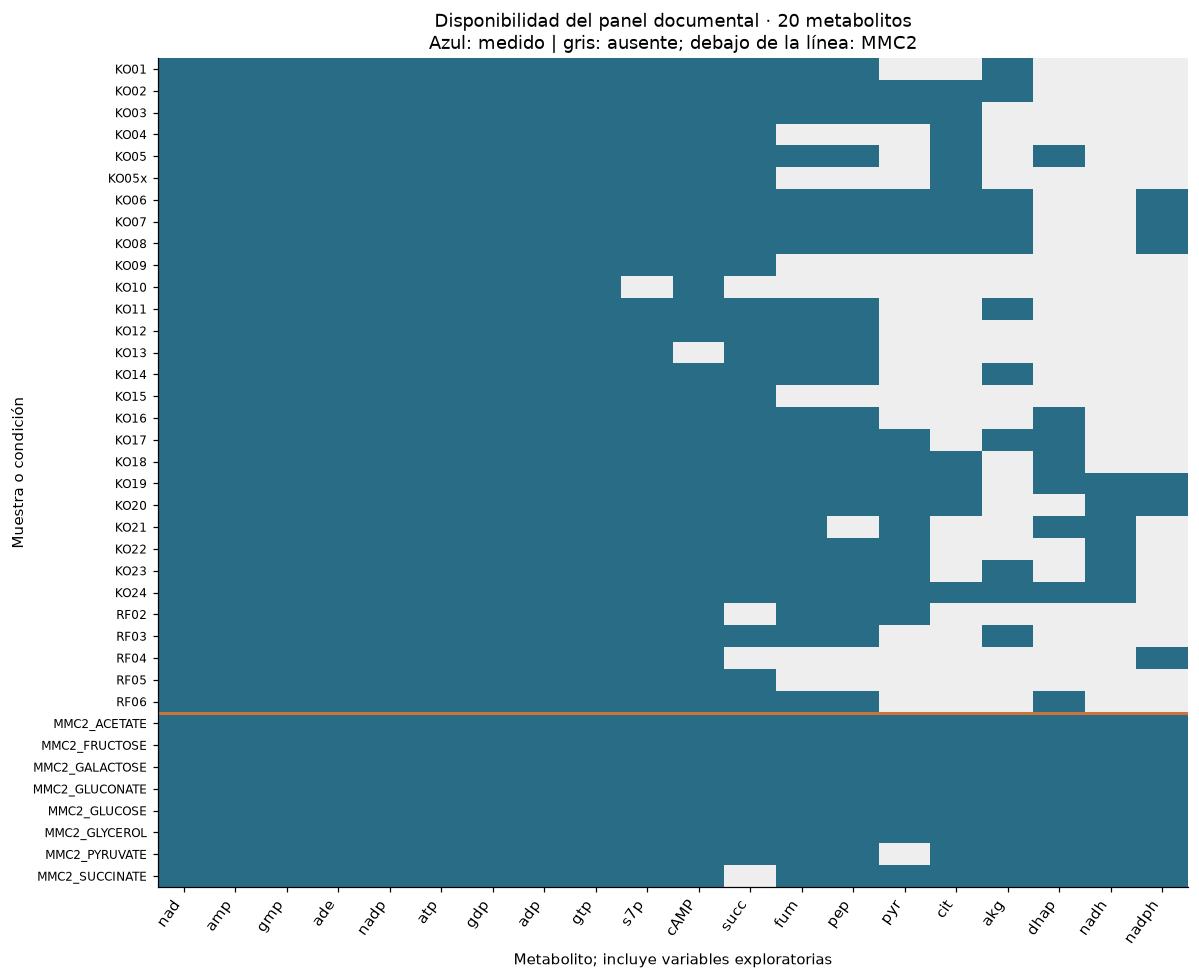

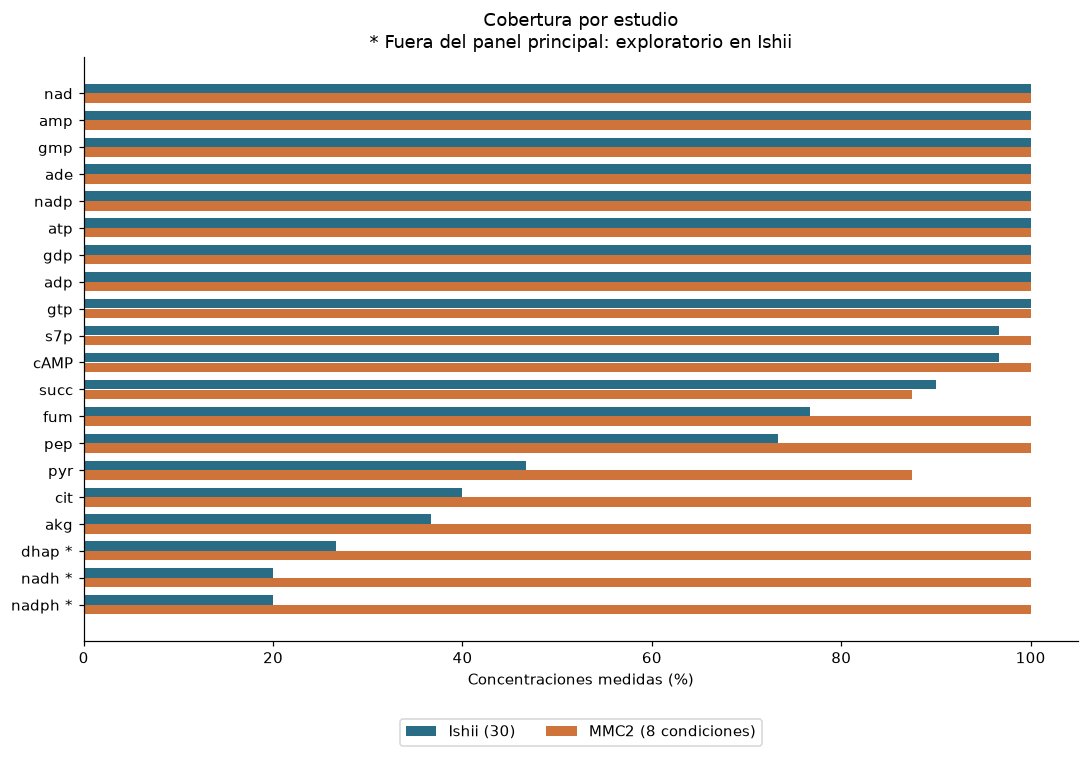

In [24]:
assert matriz_A_mM.shape == (30, len(seleccion))
assert matriz_B_mM.shape == (38, len(seleccion))
pd.testing.assert_frame_equal(matriz_A_mM, matriz_B_mM.loc[cohorte])
assert matriz_A_mM.columns.equals(matriz_B_mM.columns)
assert matriz_B_mM.index.is_unique
assert np.isfinite(matriz_B_mM.to_numpy()[matriz_B_mM.notna()]).all()
assert np.allclose(matriz_B_R.loc['MMC2_GLUCOSE'], 1)

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
orden_grafico = elegibilidad.sort_values('n_observados_A', ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(base_documental[orden_grafico].notna(), aspect='auto',
          cmap=ListedColormap(['#eeeeee', '#286d85']), vmin=0, vmax=1)
ax.set_xticks(range(len(orden_grafico)), orden_grafico, rotation=55, ha='right')
ax.set_yticks(range(len(base_documental)), base_documental.index, fontsize=8)
ax.axhline(29.5, color='#ce743a', linewidth=2)
ax.set_title('Disponibilidad del panel documental · 20 metabolitos\nAzul: medido | gris: ausente; debajo de la línea: MMC2')
ax.set_xlabel('Metabolito; incluye variables exploratorias')
ax.set_ylabel('Muestra o condición')
fig.tight_layout()
fig.savefig(SALIDA / 'figuras/01_disponibilidad.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(orden_grafico))
ax.barh(y - 0.18, elegibilidad.loc[orden_grafico, 'cobertura_pct_A'],
        height=0.35, label='Ishii (30)', color='#286d85')
ax.barh(y + 0.18, mmc2_homologada[orden_grafico].notna().mean() * 100,
        height=0.35, label='MMC2 (8 condiciones)', color='#ce743a')
ax.set_yticks(y, [m + (' *' if m not in seleccion else '') for m in orden_grafico])
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_xlabel('Concentraciones medidas (%)')
ax.set_title('Cobertura por estudio\n* Fuera del panel principal: exploratorio en Ishii')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout()
fig.savefig(SALIDA / 'figuras/02_cobertura.png', dpi=180)
plt.show()

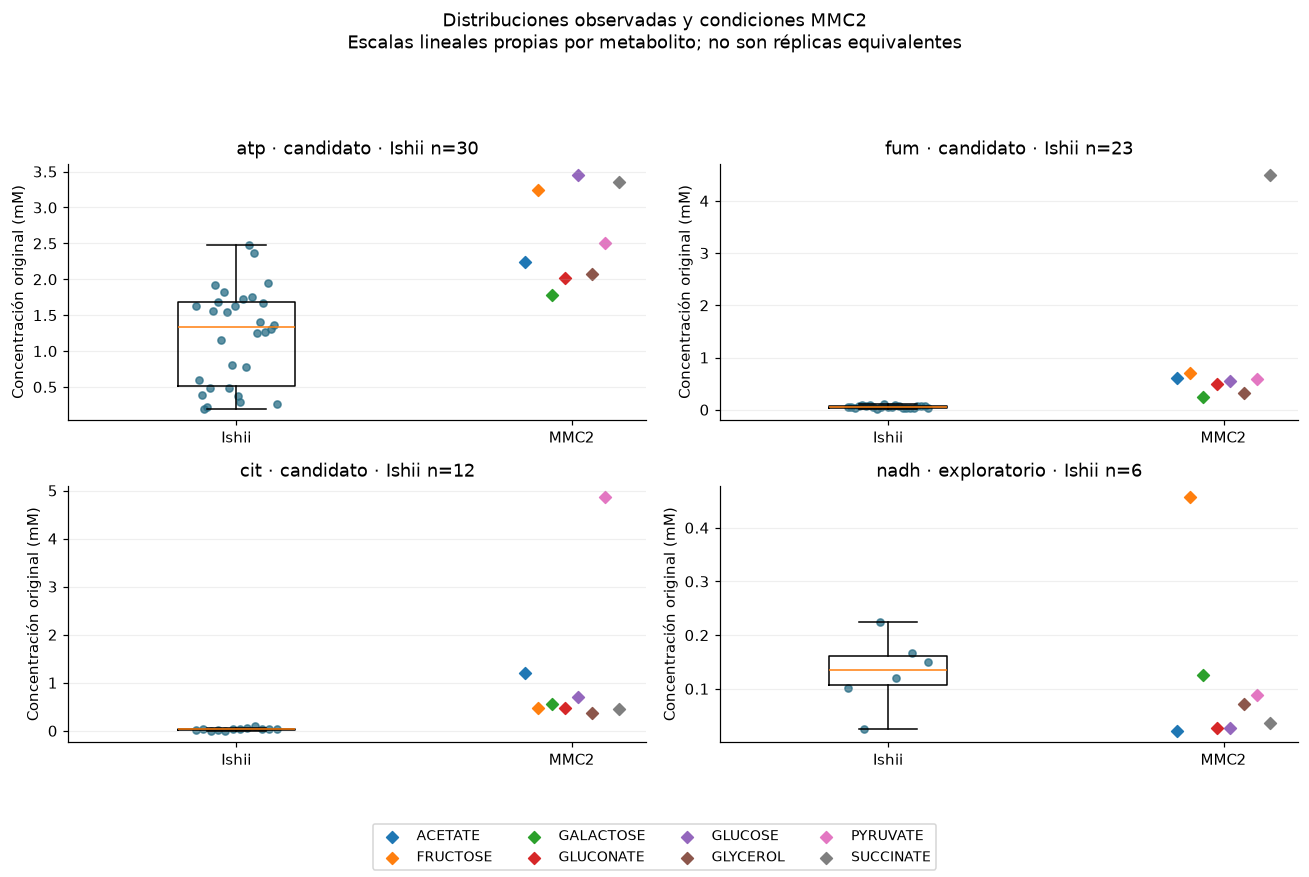

In [25]:
# Casos elegidos por disponibilidad, no por resultados de imputación.
representativos = ['atp', 'fum', 'cit', 'nadh']
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
colores = plt.get_cmap('tab10').colors
for ax, metabolito in zip(ejes.flat, representativos):
    valores = ishii_homologada[metabolito].dropna()
    ax.boxplot([valores], positions=[0], widths=0.35, showfliers=False)
    ax.scatter(np.linspace(-0.12, 0.12, len(valores)), valores,
               s=22, alpha=0.75, color='#286d85', label=f'Ishii, n={len(valores)}')
    for i, muestra in enumerate(mmc2_homologada.index):
        valor = mmc2_homologada.loc[muestra, metabolito]
        if pd.notna(valor):
            ax.scatter(1 + (i - 3.5) * 0.04, valor, color=colores[i],
                       marker='D', s=30, label=muestra.removeprefix('MMC2_'))
    ax.set_xticks([0, 1], ['Ishii', 'MMC2'])
    ax.set_ylabel('Concentración original (mM)')
    estado = 'candidato' if metabolito in seleccion else 'exploratorio'
    ax.set_title(f'{metabolito} · {estado} · Ishii n={len(valores)}')
    ax.grid(axis='y', alpha=0.2)
handles, etiquetas = ejes[0, 0].get_legend_handles_labels()
fig.legend(handles[1:], etiquetas[1:], loc='lower center', ncol=4, fontsize=9)
fig.suptitle('Distribuciones observadas y condiciones MMC2\nEscalas lineales propias por metabolito; no son réplicas equivalentes')
fig.tight_layout(rect=[0, 0.10, 1, 0.92])
fig.savefig(SALIDA / 'figuras/03_distribuciones.png', dpi=180)
plt.show()

## 10. Exportar y comprobar integridad

`mediciones_auditadas.csv` conserva todas las posiciones originales, incluidos
ceros, ausencias, filas excluidas, coordenadas y conversiones. El campo
`usada_en_matrices_principales` permite distinguir las utilizadas; no se genera
una segunda copia redundante de todos los excluidos. La tabla maestra incluye
MMC4 sin fingir cobertura. `disponibilidad_ishii.csv` cubre las 579 filas analíticas,
y `elegibilidad.csv` detalla los dos escenarios del panel homologado.

Para el futuro notebook 02: cargar `panel_documental_mM.csv`, `metadatos.csv` y
`referencias_glucosa.csv`; separar filas por procedencia y recalcular elegibilidad
dentro de cada entrenamiento. Las matrices `escenario_*` son las preparadas con
el conjunto completo, útiles para la imputación final una vez validado el método.
No se exportan máscaras artificiales ni predicciones en esta etapa.

In [26]:
maestra.to_csv(SALIDA / 'homologacion_maestra.csv', index=False)
disponibilidad.to_csv(SALIDA / 'disponibilidad_ishii.csv', index_label='analyte_id')
elegibilidad.to_csv(SALIDA / 'elegibilidad.csv', index_label='metabolito')
referencias.to_csv(SALIDA / 'referencias_glucosa.csv', index_label='metabolito')
conversiones.to_csv(SALIDA / 'conversiones.csv', index=False)
metadatos.to_csv(SALIDA / 'metadatos.csv')
mediciones.to_csv(SALIDA / 'mediciones_auditadas.csv', index=False)
base_documental.to_csv(SALIDA / 'panel_documental_mM.csv')
for nombre, matriz in [('escenario_A_mM', matriz_A_mM), ('escenario_A_R', matriz_A_R),
                       ('escenario_B_mM', matriz_B_mM), ('escenario_B_R', matriz_B_R)]:
    matriz.to_csv(SALIDA / f'{nombre}.csv')
    leida = pd.read_csv(SALIDA / f'{nombre}.csv', index_col=0)
    leida.columns.name = matriz.columns.name
    pd.testing.assert_frame_equal(matriz, leida, check_exact=False,
                                  rtol=1e-12, atol=1e-14)

for nombre, esperado in huellas.items():
    assert hashlib.sha256((FUENTES / nombre).read_bytes()).hexdigest() == esperado

verificacion = {
    'fecha': '2026-11-09', 'fuentes_sha256': huellas,
    'version_base': 'IPre_Ampliado.zip, 2026-10-22',
    'posiciones_verificadas_con_excel': len(mediciones),
    'conversion_anterior_equivalente': True,
    'filas_analiticas_ishii_intracelulares': 579,
    'panel_documental': panel_documental, 'panel_principal': seleccion,
    'dimensiones_A': list(matriz_A_mM.shape), 'dimensiones_B': list(matriz_B_mM.shape),
    'medidos_A': int(matriz_A_mM.notna().sum().sum()),
    'faltantes_A': int(matriz_A_mM.isna().sum().sum()),
    'medidos_B': int(matriz_B_mM.notna().sum().sum()),
    'faltantes_B': int(matriz_B_mM.isna().sum().sum()),
    'umbrales': {'candidata': MIN_CANDIDATA, 'exploratoria_y_pares': MIN_EXPLORATORIA,
                 'predictores': MIN_PREDICTORES},
    'controles': ['etiquetas y protocolos contra Excel', 'celdas y SD contra Excel', 'unicidad', 'referencias positivas con SD',
                 'mM-R reversible', 'mismos valores Ishii A/B',
                 'relectura CSV', 'fuentes intactas', 'elegibilidad solo entrenamiento'],
    'python': sys.version.split()[0], 'pandas': pd.__version__,
    'numpy': np.__version__, 'openpyxl': openpyxl.__version__,
    'imputaciones_ejecutadas': False,
    'verificacion_notebook': '11 celdas ejecutadas en orden mediante IPython; no interfaz Jupyter',
}
(SALIDA / 'verificacion.json').write_text(
    json.dumps(verificacion, ensure_ascii=False, indent=2) + '\n', encoding='utf-8'
)
print('A:', matriz_A_mM.shape, '| B:', matriz_B_mM.shape)
print('Huecos Ishii conservados:', verificacion['faltantes_A'])
print('Resultados en:', SALIDA.name)

A: (30, 17) | B: (38, 17)
Huecos Ishii conservados: 73
Resultados en: auditoria


### Decisiones y pendientes

- Se verificaron 20.483 posiciones de concentración contra los Excel. La conversión
  previa a mM se conserva porque coincide con las fuentes.
- El inventario completo no equivale al panel imputable. Se aceptaron 20
  correspondencias nominales; las demás siguen conservadas con motivos específicos
  o como homologación pendiente. Se necesita evidencia de estándares para resolver
  estereoquímica y señales alternativas, no solo más nombres de bases químicas.
- Los umbrales y la variación seleccionan candidatos, no validan sus estimaciones.
  Las celdas no detectadas pueden estar censuradas: ocultar valores medidos no
  reproduce necesariamente ese mecanismo. Faltan límites analíticos por celda.
- La condición glucosa de MMC2 sigue siendo el denominador común. Su tiempo/OD
  provienen de una figura y son aproximados, no criterios de emparejamiento.
- B es un experimento de transferencia entre estudios con las ocho condiciones
  documentadas; la normalización no corrige diferencias de cultivo o extracción.
  La utilidad de añadirlas deberá demostrarse con los mismos casos Ishii.
- KO05x conserva su identidad propia, grupo pfkA y serie 4; la dilución se documenta
  desde la leyenda del Excel. Fecha y correspondencia exacta con S2 siguen pendientes.
- Las matrices no están completas por diseño. `02_imputacion_evaluacion.ipynb` valida
  primero y después estima los candidatos reales. Este notebook conserva únicamente la preparación.

La inspección de las distribuciones muestra diferencias de escala importantes,
por ejemplo para fumarato y citrato entre los estudios. No se eliminan condiciones
por ese resultado ni se corrigen valores para igualarlos. Es una advertencia
concreta para evaluar B sobre las mismas verdades Ishii y comparar cobertura y
error; una mejora no puede darse por supuesta.

**Fuentes documentales:** `ishii.xlsx`, generals!A10:B10, B20:C22, A49 y A52:C60;
Ishii, Supporting Online Material, DOI 10.1126/science.1132067, PDF pp.2 y 10–11;
`mmc2.xlsx`, Conversion Factors!A5:B6, Metabolite concentrations y Measurement Sampling;
Gerosa, Extended Experimental Procedures, DOI 10.1016/j.cels.2015.09.008,
PDF pp.7 y 9; `mmc3.xlsx`, Metabolite concentrations; `mmc4.xlsx`, metabolites.

**Apoyo de nomenclatura:** [DHAP](https://www.kegg.jp/entry/C00111),
[AMP](https://www.kegg.jp/entry/C00020), [GMP](https://www.kegg.jp/entry/C00144),
[GDP](https://www.kegg.jp/entry/C00035), [GTP](https://www.kegg.jp/entry/C00044),
[cAMP](https://www.kegg.jp/entry/C00575). La identidad de fuente y la vinculación
al modelo se mantienen separadas de la verificación química experimental.